In [1]:
import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import torch
import torch.nn as nn

In [2]:
import os
for dirname, _, filenames in os.walk('C:/Users/Tharunraj_S/Desktop/Mini_project/Codes'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

C:/Users/Tharunraj_S/Desktop/Mini_project/Codes\BioMarkers.ipynb
C:/Users/Tharunraj_S/Desktop/Mini_project/Codes\fusion.ipynb
C:/Users/Tharunraj_S/Desktop/Mini_project/Codes\kidney_disease.csv
C:/Users/Tharunraj_S/Desktop/Mini_project/Codes\pytorch_predict.ipynb
C:/Users/Tharunraj_S/Desktop/Mini_project/Codes\Pytorch_train.ipynb
C:/Users/Tharunraj_S/Desktop/Mini_project/Codes\test.csv
C:/Users/Tharunraj_S/Desktop/Mini_project/Codes\trained_model.pt
C:/Users/Tharunraj_S/Desktop/Mini_project/Codes\.ipynb_checkpoints\BioMarkers-checkpoint.ipynb
C:/Users/Tharunraj_S/Desktop/Mini_project/Codes\.ipynb_checkpoints\Final-checkpoint.ipynb
C:/Users/Tharunraj_S/Desktop/Mini_project/Codes\.ipynb_checkpoints\fusion-checkpoint.ipynb
C:/Users/Tharunraj_S/Desktop/Mini_project/Codes\.ipynb_checkpoints\pytorch_predict-checkpoint.ipynb
C:/Users/Tharunraj_S/Desktop/Mini_project/Codes\.ipynb_checkpoints\Pytorch_train-checkpoint.ipynb
C:/Users/Tharunraj_S/Desktop/Mini_project/Codes\Final\modified_data.csv
C

In [5]:
Data="C:/Users/Tharunraj_S/Desktop/Mini_project/Codes\kidney_disease.csv"
df=pd.read_csv(Data)
df.head()

,id,age,bp,sg,al,su,rbc,pc,pcc,ba,...,pcv,wc,rc,htn,dm,cad,appet,pe,ane,classification
0,0,48.0,80.0,1.020,1.0,0.0,NaN,normal,notpresent,notpresent,...,44,7800,5.2,yes,yes,no,good,no,no,ckd
1,1,7.0,50.0,1.020,4.0,0.0,NaN,normal,notpresent,notpresent,...,38,6000,NaN,no,no,no,good,no,no,ckd
2,2,62.0,80.0,1.010,2.0,3.0,normal,normal,notpresent,notpresent,...,31,7500,NaN,no,yes,no,poor,no,yes,ckd
3,3,48.0,70.0,1.005,4.0,0.0,normal,abnormal,present,notpresent,...,32,6700,3.9,yes,no,no,poor,yes,yes,ckd
4,4,51.0,80.0,1.010,2.0,0.0,normal,normal,notpresent,notpresent,...,35,7300,4.6,no,no,no,good,no,no,ckd


In [6]:
# dropping id column
df.drop('id', axis = 1, inplace = True)

In [7]:
# rename column names to make it more meaningful
df.columns = ['age', 'blood_pressure', 'specific_gravity', 'albumin', 'sugar', 'red_blood_cells', 'pus_cell',
              'pus_cell_clumps', 'bacteria', 'blood_glucose_random', 'blood_urea', 'serum_creatinine', 'sodium',
              'potassium', 'haemoglobin', 'packed_cell_volume', 'white_blood_cell_count', 'red_blood_cell_count',
              'hypertension', 'diabetes_mellitus', 'coronary_artery_disease', 'appetite', 'peda_edema',
              'anemia', 'class']

In [8]:
df.describe()

,age,blood_pressure,specific_gravity,albumin,sugar,blood_glucose_random,blood_urea,serum_creatinine,sodium,potassium,haemoglobin
count,391.000000,388.000000,353.000000,354.000000,351.000000,356.000000,381.000000,383.000000,313.000000,312.000000,348.000000
mean,51.483376,76.469072,1.017408,1.016949,0.450142,148.036517,57.425722,3.072454,137.528754,4.627244,12.526437
std,17.169714,13.683637,0.005717,1.352679,1.099191,79.281714,50.503006,5.741126,10.408752,3.193904,2.912587
min,2.000000,50.000000,1.005000,0.000000,0.000000,22.000000,1.500000,0.400000,4.500000,2.500000,3.100000
25%,42.000000,70.000000,1.010000,0.000000,0.000000,99.000000,27.000000,0.900000,135.000000,3.800000,10.300000
50%,55.000000,80.000000,1.020000,0.000000,0.000000,121.000000,42.000000,1.300000,138.000000,4.400000,12.650000
75%,64.500000,80.000000,1.020000,2.000000,0.000000,163.000000,66.000000,2.800000,142.000000,4.900000,15.000000
max,90.000000,180.000000,1.025000,5.000000,5.000000,490.000000,391.000000,76.000000,163.000000,47.000000,17.800000


In [9]:
# replace some incorrect values
df['diabetes_mellitus'].replace(to_replace = {'\tno':'no','\tyes':'yes',' yes':'yes'},inplace=True)

df['coronary_artery_disease'] = df['coronary_artery_disease'].replace(to_replace = '\tno', value='no')

df['class'] = df['class'].replace(to_replace = {'ckd\t': 'ckd', 'notckd': 'not ckd'})

In [10]:
# converting necessary columns to numerical type
df['packed_cell_volume'] = pd.to_numeric(df['packed_cell_volume'], errors='coerce')
df['white_blood_cell_count'] = pd.to_numeric(df['white_blood_cell_count'], errors='coerce')
df['red_blood_cell_count'] = pd.to_numeric(df['red_blood_cell_count'], errors='coerce')

In [11]:
column_mappings = {
    'red_blood_cells': {'normal': 0, 'abnormal': 1},
    'pus_cell': {'normal': 0, 'abnormal': 1},
    'pus_cell_clumps': {'notpresent': 0, 'present': 1},
    'bacteria': {'notpresent': 0, 'present': 1},
    'hypertension': {'no': 0, 'yes': 1},
    'diabetes_mellitus': {'no': 0, 'yes': 1},
    'coronary_artery_disease': {'no': 0, 'yes': 1},
    'appetite': {'good': 0, 'poor': 1},
    'peda_edema': {'no': 0, 'yes': 1},
    'anemia': {'no': 0, 'yes': 1},
    'class':{'ckd':0,'not ckd':1}
}

# Apply custom mappings to the selected columns
df.replace(column_mappings, inplace=True)


In [12]:
df

,age,blood_pressure,specific_gravity,albumin,sugar,red_blood_cells,pus_cell,pus_cell_clumps,bacteria,blood_glucose_random,...,packed_cell_volume,white_blood_cell_count,red_blood_cell_count,hypertension,diabetes_mellitus,coronary_artery_disease,appetite,peda_edema,anemia,class
0,48.0,80.0,1.020,1.0,0.0,NaN,0.0,0.0,0.0,121.0,...,44.0,7800.0,5.2,1.0,1.0,0.0,0.0,0.0,0.0,0
1,7.0,50.0,1.020,4.0,0.0,NaN,0.0,0.0,0.0,NaN,...,38.0,6000.0,NaN,0.0,0.0,0.0,0.0,0.0,0.0,0
2,62.0,80.0,1.010,2.0,3.0,0.0,0.0,0.0,0.0,423.0,...,31.0,7500.0,NaN,0.0,1.0,0.0,1.0,0.0,1.0,0
3,48.0,70.0,1.005,4.0,0.0,0.0,1.0,1.0,0.0,117.0,...,32.0,6700.0,3.9,1.0,0.0,0.0,1.0,1.0,1.0,0
4,51.0,80.0,1.010,2.0,0.0,0.0,0.0,0.0,0.0,106.0,...,35.0,7300.0,4.6,0.0,0.0,0.0,0.0,0.0,0.0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
395,55.0,80.0,1.020,0.0,0.0,0.0,0.0,0.0,0.0,140.0,...,47.0,6700.0,4.9,0.0,0.0,0.0,0.0,0.0,0.0,1
396,42.0,70.0,1.025,0.0,0.0,0.0,0.0,0.0,0.0,75.0,...,54.0,7800.0,6.2,0.0,0.0,0.0,0.0,0.0,0.0,1
397,12.0,80.0,1.020,0.0,0.0,0.0,0.0,0.0,0.0,100.0,...,49.0,6600.0,5.4,0.0,0.0,0.0,0.0,0.0,0.0,1
398,17.0,60.0,1.025,0.0,0.0,0.0,0.0,0.0,0.0,114.0,...,51.0,7200.0,5.9,0.0,0.0,0.0,0.0,0.0,0.0,1


In [15]:
# Convert Series to numpy array
X = df.drop("class", axis=1)
y = df["class"]

In [16]:
import numpy as np

#Data Normalization

import numpy as np

# Define default values for each column
column_defaults = {
    'age': 51.483376,
    'blood_pressure': 76.469072,
    'specific_gravity': 1.017408,
    'albumin': 0,  # Example albumin level
    'sugar': 0,  # Example sugar level
    'red_blood_cells': 0,  # Example red blood cell presence (1 for normal, 0 for abnormal)
    'pus_cell': 1,  # Example pus cell presence (1 for normal, 0 for abnormal)
    'pus_cell_clumps': 0,  # Example pus cell clumps presence (1 for present, 0 for absent)
    'bacteria': 0,  # Example bacteria presence (1 for present, 0 for absent)
    'blood_glucose_random': 120,
    'blood_urea': 57.425722,
    'serum_creatinine': 0.450142,
    'sodium': 137.528754,
    'potassium': 4.627244,
    'haemoglobin': 12.526437,
    'packed_cell_volume': 45,  # Example packed cell volume percentage
    'white_blood_cell_count': 7000,  # Example white blood cell count cells/μL
    'red_blood_cell_count': 5,  # Example red blood cell count million cells/μL
    'hypertension': 0,  # Example hypertension presence (1 for yes, 0 for no)
    'diabetes_mellitus': 0,  # Example diabetes mellitus presence (1 for yes, 0 for no)
    'coronary_artery_disease': 0,  # Example coronary artery disease presence (1 for yes, 0 for no)
    'appetite': 0,  # Example appetite (0 for good, 1 for poor)
    'peda_edema': 0,  # Example pedal edema presence (1 for yes, 0 for no)
    'anemia': 0  # Example anemia presence (1 for yes, 0 for no)
}

# Replace null values with custom default values using an if-else condition
for col_name in column_defaults.keys():
    default_value = column_defaults[col_name]
    X[col_name] = X[col_name].fillna(default_value)
 

In [17]:
y

0      0
1      0
2      0
3      0
4      0
      ..
395    1
396    1
397    1
398    1
399    1
Name: class, Length: 400, dtype: int64

In [20]:
from sklearn.model_selection import train_test_split
import numpy as np

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

X_train_array = np.array(X_train)  # Convert Series to numpy array
X_test_array = np.array(X_test)

y_train_array = y_train.to_numpy()  # Convert Series to numpy array
y_test_array = y_test.to_numpy()


# Convert to PyTorch tensors
X_train_tensor = torch.tensor(X_train_array, dtype=torch.float32)
X_test_tensor = torch.tensor(X_test_array, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train_array, dtype=torch.long)
y_test_tensor = torch.tensor(y_test_array, dtype=torch.long)


In [35]:
from torch.utils.data import DataLoader, TensorDataset

# Create a TensorDataset
train_dataset = TensorDataset(X_train_tensor, y_train_tensor)

# Create a DataLoader
batch_size = 32  # Adjust this based on your preferences
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)


In [36]:
from torch.utils.data import DataLoader, TensorDataset

# Create a TensorDataset
test_dataset = TensorDataset(X_test_tensor, y_test_tensor)

# Create a DataLoader
batch_size = 64  # Adjust this based on your preferences
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)  # No need to shuffle for evaluation


In [37]:
class KidneyCNN(nn.Module):
    def __init__(self, input_size, num_classes):
        super(KidneyCNN, self).__init__()
        self.conv1 = nn.Conv1d(1, 32, kernel_size=3)
        self.conv2 = nn.Conv1d(32, 64, kernel_size=3)
        self.fc1 = nn.Linear(64 * (input_size - 4), 128)
        self.fc2 = nn.Linear(128, num_classes)

    def forward(self, x):
        x = x.unsqueeze(1)  # Add a channel dimension (batch_size, 1, input_size)
        x = torch.relu(self.conv1(x))
        x = torch.relu(self.conv2(x))
        x = x.view(x.size(0), -1)  # Flatten the tensor
        x = torch.relu(self.fc1(x))
        x = self.fc2(x)
        return x


In [38]:
   
input_size = 24 # number of biomarkers
hidden_size = 64 # choose an appropriate value
output_size=num_classes = 2 

model = KidneyCNN(input_size, output_size)

criterion = nn.CrossEntropyLoss()  # For classification

optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

num_epochs = 50# choose an appropriate value


In [39]:
# Initialize an empty list to store loss values for each epoch
epoch_losses = []

for epoch in range(num_epochs):
    model.train()
    running_loss = 0.0

    for inputs, labels in train_loader: 
        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        running_loss += loss.item()

    # Calculate average loss for the current epoch
    epoch_loss = running_loss / len(train_loader)
    epoch_losses.append(epoch_loss)  # Store the loss for this epoch

    print(f'Epoch [{epoch+1}/{num_epochs}], Loss: {epoch_loss}')




Epoch [1/50], Loss: 77.91946269869804
Epoch [2/50], Loss: 5.560103043913841
Epoch [3/50], Loss: 6.803410577774048
Epoch [4/50], Loss: 14.54994707107544
Epoch [5/50], Loss: 7.821718692779541
Epoch [6/50], Loss: 3.242471143603325
Epoch [7/50], Loss: 2.083536374568939
Epoch [8/50], Loss: 2.909582495689392
Epoch [9/50], Loss: 3.8391098856925963
Epoch [10/50], Loss: 1.64210464656353
Epoch [11/50], Loss: 0.8532393664121628
Epoch [12/50], Loss: 0.4451663464307785
Epoch [13/50], Loss: 0.6357635617256164
Epoch [14/50], Loss: 0.8828276038169861
Epoch [15/50], Loss: 0.8909721732139587
Epoch [16/50], Loss: 1.4792284414172172
Epoch [17/50], Loss: 0.9056856751441955
Epoch [18/50], Loss: 1.0840588435530663
Epoch [19/50], Loss: 0.5413694947957992
Epoch [20/50], Loss: 0.4765459567308426
Epoch [21/50], Loss: 0.4359393134713173
Epoch [22/50], Loss: 0.5882403671741485
Epoch [23/50], Loss: 0.3927827402949333
Epoch [24/50], Loss: 0.34008674174547193
Epoch [25/50], Loss: 0.3678079813718796
Epoch [26/50], Los

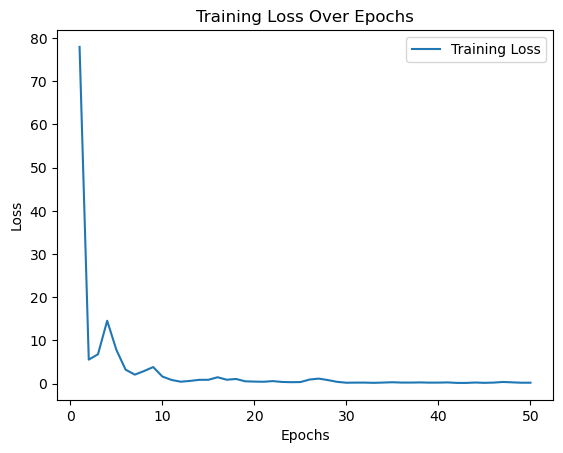

In [40]:
# Plot the loss graph after training is completed
import matplotlib.pyplot as plt
plt.plot(range(1, num_epochs+1), epoch_losses, label='Training Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.title('Training Loss Over Epochs')
plt.legend()
plt.show()

In [41]:
from sklearn.metrics import classification_report

with torch.no_grad():
    all_predictions = []
    all_labels = []
    for inputs, labels in test_loader:
        outputs = model(inputs)
        _, predicted = torch.max(outputs, 1)
        all_predictions.extend(predicted.tolist())
        all_labels.extend(labels.tolist())

report = classification_report(all_labels, all_predictions)
print(report)


              precision    recall  f1-score   support

           0       1.00      0.94      0.97        52
           1       0.90      1.00      0.95        28

    accuracy                           0.96        80
   macro avg       0.95      0.97      0.96        80
weighted avg       0.97      0.96      0.96        80



In [42]:
model.eval()  # Set model to evaluation mode
total_correct = 0
total_samples = 0

with torch.no_grad():
    for inputs, labels in test_loader:
        outputs = model(inputs)
        _, predicted = torch.max(outputs, 1)
        total_samples += labels.size(0)
        total_correct += (predicted == labels).sum().item()

accuracy = total_correct / total_samples
print(f'Accuracy on the test set: {accuracy * 100:.2f}%')


Accuracy on the test set: 96.25%


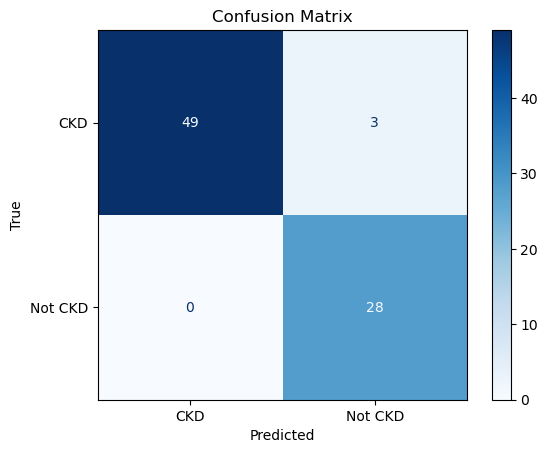

In [43]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

# Assuming you have already defined the 'all_labels' and 'all_predictions' lists

# Calculate the confusion matrix
conf_matrix = confusion_matrix(all_labels, all_predictions)

# Define class names (replace with your class names)
class_names = ['CKD', 'Not CKD']

# Create the confusion matrix plot
disp = ConfusionMatrixDisplay(conf_matrix, display_labels=class_names)
disp.plot(cmap=plt.cm.Blues)

# Add title and axis labels
plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("True")

# Show the plot
plt.show()


In [44]:
# Save the model to a file
model_path = 'C:/Users/Tharunraj_S/Desktop/Mini_project/Codes/Final/trained_model.pt'
torch.save(model.state_dict(), model_path)

print(f'Model saved to {model_path}')


Model saved to C:/Users/Tharunraj_S/Desktop/Mini_project/Codes/Final/trained_model.pt


Epoch [1/1000], Loss: 0.18543831817805767, mAP: 0.9316325069546719
Epoch [2/1000], Loss: 0.1943308874964714, mAP: 0.9344258589511754
Epoch [3/1000], Loss: 0.325969747081399, mAP: 0.8824038461538463
Epoch [4/1000], Loss: 0.23946280106902124, mAP: 0.9
Epoch [5/1000], Loss: 0.4582113683223724, mAP: 0.8495000000000001
Epoch [6/1000], Loss: 0.7304578922688961, mAP: 0.809805065364527
Epoch [7/1000], Loss: 0.9176361426711083, mAP: 0.7871558204244362
Epoch [8/1000], Loss: 0.5999573230743408, mAP: 0.8225244969648413
Epoch [9/1000], Loss: 0.2326691471040249, mAP: 0.8932036247334754
Epoch [10/1000], Loss: 0.21616885364055632, mAP: 0.9222614682657545
Epoch [11/1000], Loss: 0.32041368521749974, mAP: 0.8969549212089898
Epoch [12/1000], Loss: 0.5038804583251476, mAP: 0.8850870944020588
Epoch [13/1000], Loss: 0.24478141516447066, mAP: 0.9126336098386364
Epoch [14/1000], Loss: 0.15619873702526094, mAP: 0.947137798420713
Epoch [15/1000], Loss: 0.15102647319436074, mAP: 0.9535150257540816
Epoch [16/1000]

Epoch [125/1000], Loss: 0.09645774569362402, mAP: 0.9658367037411526
Epoch [126/1000], Loss: 0.10114046139642596, mAP: 0.9658367037411526
Epoch [127/1000], Loss: 0.10324634052813053, mAP: 0.9689238667975782
Epoch [128/1000], Loss: 0.10420136265456677, mAP: 0.9658367037411526
Epoch [129/1000], Loss: 0.11130986027419568, mAP: 0.9565445106278814
Epoch [130/1000], Loss: 0.12015803288668395, mAP: 0.9719775521523435
Epoch [131/1000], Loss: 0.13808401860296726, mAP: 0.9565445106278814
Epoch [132/1000], Loss: 0.1033256920054555, mAP: 0.9596251953304531
Epoch [133/1000], Loss: 0.10275175012648105, mAP: 0.9565445106278814
Epoch [134/1000], Loss: 0.09815647341310978, mAP: 0.9658367037411526
Epoch [135/1000], Loss: 0.0987187473103404, mAP: 0.9627524376810411
Epoch [136/1000], Loss: 0.14008975252509118, mAP: 0.9533568809594527
Epoch [137/1000], Loss: 0.19136892035603523, mAP: 0.9409906700983546
Epoch [138/1000], Loss: 0.18808274529874325, mAP: 0.9375954355990259
Epoch [139/1000], Loss: 0.1848261734

Epoch [248/1000], Loss: 0.1392023011110723, mAP: 0.9375954355990259
Epoch [249/1000], Loss: 0.12393927983939648, mAP: 0.9502153846153847
Epoch [250/1000], Loss: 0.11682884064503014, mAP: 0.947068709621093
Epoch [251/1000], Loss: 0.114703188277781, mAP: 0.9626615384615385
Epoch [252/1000], Loss: 0.0830313317477703, mAP: 0.9720482121518522
Epoch [253/1000], Loss: 0.07217361070215703, mAP: 0.9813307692307692
Epoch [254/1000], Loss: 0.08739389330148697, mAP: 0.9720141285756718
Epoch [255/1000], Loss: 0.08839235939085484, mAP: 0.9689238667975782
Epoch [256/1000], Loss: 0.08100930685177446, mAP: 0.9813055464121133
Epoch [257/1000], Loss: 0.07211413383483886, mAP: 0.9844319734179685
Epoch [258/1000], Loss: 0.07851921510882676, mAP: 0.9720482121518522
Epoch [259/1000], Loss: 0.07200610674917698, mAP: 0.9782332111144113
Epoch [260/1000], Loss: 0.07263085301965475, mAP: 0.9751076923076922
Epoch [261/1000], Loss: 0.10280355140566826, mAP: 0.9688425773535222
Epoch [262/1000], Loss: 0.1005114840343

Epoch [369/1000], Loss: 0.07880612341687084, mAP: 0.9844319734179685
Epoch [370/1000], Loss: 0.0772470966912806, mAP: 0.9720141285756718
Epoch [371/1000], Loss: 0.06966047370806336, mAP: 0.9781743517631425
Epoch [372/1000], Loss: 0.06701317995321006, mAP: 0.9720141285756718
Epoch [373/1000], Loss: 0.054687181301414964, mAP: 0.9875370309414089
Epoch [374/1000], Loss: 0.05063039492815733, mAP: 0.9906461507556324
Epoch [375/1000], Loss: 0.0814207243733108, mAP: 0.9719775521523435
Epoch [376/1000], Loss: 0.0571593789383769, mAP: 0.9844319734179685
Epoch [377/1000], Loss: 0.14349563543219118, mAP: 0.9595231308867183
Epoch [378/1000], Loss: 0.07987490186933428, mAP: 0.9781743517631425
Epoch [379/1000], Loss: 0.08944501418154686, mAP: 0.9594666532744073
Epoch [380/1000], Loss: 0.07890849029645323, mAP: 0.9688846153846153
Epoch [381/1000], Loss: 0.06833306336775422, mAP: 0.968797717799513
Epoch [382/1000], Loss: 0.05792590766213834, mAP: 0.9813307692307692
Epoch [383/1000], Loss: 0.06121877161

Epoch [489/1000], Loss: 0.06187693383544683, mAP: 0.9875190871198052
Epoch [490/1000], Loss: 0.05200326500926167, mAP: 0.9720141285756718
Epoch [491/1000], Loss: 0.08621155610308051, mAP: 0.9655975629982066
Epoch [492/1000], Loss: 0.04732497856020927, mAP: 0.9906322655644537
Epoch [493/1000], Loss: 0.04801537678577006, mAP: 0.9843871092740895
Epoch [494/1000], Loss: 0.039547933358699085, mAP: 0.9875190871198052
Epoch [495/1000], Loss: 0.04023875743150711, mAP: 0.9906322655644537
Epoch [496/1000], Loss: 0.03628260027617216, mAP: 0.9937595435599025
Epoch [497/1000], Loss: 0.041345748538151386, mAP: 0.9875370309414089
Epoch [498/1000], Loss: 0.0354775704909116, mAP: 0.9875190871198052
Epoch [499/1000], Loss: 0.046965256612747905, mAP: 0.9813055464121133
Epoch [500/1000], Loss: 0.07500531417317688, mAP: 0.9657503415195308
Epoch [501/1000], Loss: 0.04069431063253433, mAP: 0.9906322655644537
Epoch [502/1000], Loss: 0.05550411872100085, mAP: 0.9812786306797078
Epoch [503/1000], Loss: 0.066971

Epoch [611/1000], Loss: 0.0376171998330392, mAP: 0.9906322655644537
Epoch [612/1000], Loss: 0.027771468553692103, mAP: 0.99375
Epoch [613/1000], Loss: 0.048892464820528406, mAP: 0.9781743517631425
Epoch [614/1000], Loss: 0.023756063997279853, mAP: 0.9906461507556324
Epoch [615/1000], Loss: 0.02185683655552566, mAP: 0.9937595435599025
Epoch [616/1000], Loss: 0.024945954931899904, mAP: 0.9906322655644537
Epoch [617/1000], Loss: 0.02774298102594912, mAP: 0.9875190871198052
Epoch [618/1000], Loss: 0.02900318391621113, mAP: 0.9906322655644537
Epoch [619/1000], Loss: 0.03530125613324344, mAP: 0.9906461507556324
Epoch [620/1000], Loss: 0.027219255547970535, mAP: 0.9937595435599025
Epoch [621/1000], Loss: 0.034506877628155054, mAP: 0.9906461507556324
Epoch [622/1000], Loss: 0.021775454701855778, mAP: 0.9875
Epoch [623/1000], Loss: 0.02592346058227122, mAP: 0.9906461507556324
Epoch [624/1000], Loss: 0.02905187658034265, mAP: 0.9906322655644537
Epoch [625/1000], Loss: 0.025409309216775, mAP: 0.9

Epoch [736/1000], Loss: 0.012772645219229162, mAP: 0.9937595435599025
Epoch [737/1000], Loss: 0.011156771029345692, mAP: 0.9937595435599025
Epoch [738/1000], Loss: 0.012535388045944274, mAP: 1.0
Epoch [739/1000], Loss: 0.01907564385328442, mAP: 0.9937595435599025
Epoch [740/1000], Loss: 0.018929514012415893, mAP: 0.9937595435599025
Epoch [741/1000], Loss: 0.018717595422640444, mAP: 0.9937398770713068
Epoch [742/1000], Loss: 0.018809291085926817, mAP: 0.9875370309414089
Epoch [743/1000], Loss: 0.043928804848110306, mAP: 0.9875
Epoch [744/1000], Loss: 0.025620494037866592, mAP: 0.99375
Epoch [745/1000], Loss: 0.01753767720219912, mAP: 0.9937595435599025
Epoch [746/1000], Loss: 0.013876347430050373, mAP: 0.996877421854818
Epoch [747/1000], Loss: 0.016404104686807842, mAP: 0.9937595435599025
Epoch [748/1000], Loss: 0.009355745324864984, mAP: 0.996877421854818
Epoch [749/1000], Loss: 0.009918759972788394, mAP: 0.996877421854818
Epoch [750/1000], Loss: 0.01194079064298421, mAP: 0.99687742185

Epoch [859/1000], Loss: 0.0830893304606434, mAP: 0.9781419529837251
Epoch [860/1000], Loss: 0.061253433571982895, mAP: 0.9749595082852277
Epoch [861/1000], Loss: 0.08972838767804206, mAP: 0.9718967966933608
Epoch [862/1000], Loss: 0.09708059754484566, mAP: 0.9624392624278417
Epoch [863/1000], Loss: 0.04325400178495329, mAP: 0.9843625286355486
Epoch [864/1000], Loss: 0.015490702632814646, mAP: 0.996877421854818
Epoch [865/1000], Loss: 0.011712177156005055, mAP: 0.99375
Epoch [866/1000], Loss: 0.008964062901213765, mAP: 1.0
Epoch [867/1000], Loss: 0.015074287017341703, mAP: 0.9906322655644537
Epoch [868/1000], Loss: 0.008571924761781702, mAP: 0.996877421854818
Epoch [869/1000], Loss: 0.008283646428026259, mAP: 0.996877421854818
Epoch [870/1000], Loss: 0.00868869605474174, mAP: 1.0
Epoch [871/1000], Loss: 0.008273890591226518, mAP: 0.996877421854818
Epoch [872/1000], Loss: 0.011329007486347109, mAP: 0.9968725057271095
Epoch [873/1000], Loss: 0.016990244973567315, mAP: 0.99375
Epoch [874/1

Epoch [994/1000], Loss: 0.004100687942991499, mAP: 1.0
Epoch [995/1000], Loss: 0.007357619711547159, mAP: 0.996877421854818
Epoch [996/1000], Loss: 0.004096586150262737, mAP: 1.0
Epoch [997/1000], Loss: 0.0065793611804110695, mAP: 0.9968725057271095
Epoch [998/1000], Loss: 0.018050517638766906, mAP: 0.9906322655644537
Epoch [999/1000], Loss: 0.004010539342652919, mAP: 1.0
Epoch [1000/1000], Loss: 0.003447133984445827, mAP: 1.0


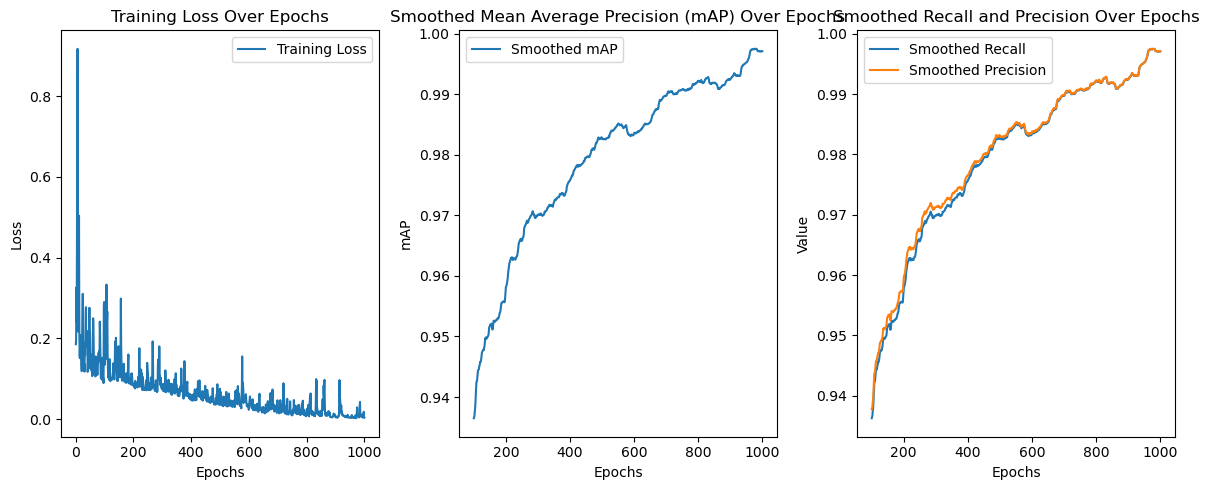

In [45]:
from sklearn.metrics import classification_report
import torch
import torch.optim as optim
import torch.nn as nn
import matplotlib.pyplot as plt
import numpy as np

# Initialize empty lists to store metrics values for each epoch
epoch_losses = []
epoch_mAPs = []
epoch_recalls = []
epoch_precisions = []

# Set the window size for moving average smoothing
moving_avg_window = 100
num_epochs=1000
for epoch in range(num_epochs):
    model.train()
    running_loss = 0.0
    all_predictions = []
    all_labels = []

    for inputs, labels in train_loader: 
        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        running_loss += loss.item()

        # Calculate metrics during training
        _, predicted = torch.max(outputs, 1)
        all_predictions.extend(predicted.tolist())
        all_labels.extend(labels.tolist())

    # Calculate metrics for the current epoch
    epoch_loss = running_loss / len(train_loader)
    epoch_losses.append(epoch_loss)  # Store the loss for this epoch

    report = classification_report(all_labels, all_predictions, target_names=['ckd', 'notckd'], output_dict=True)
    epoch_mAP = report['weighted avg']['f1-score']
    epoch_recalls.append(report['weighted avg']['recall'])
    epoch_precisions.append(report['weighted avg']['precision'])
    epoch_mAPs.append(epoch_mAP)  # Store the mAP for this epoch

    print(f'Epoch [{epoch+1}/{num_epochs}], Loss: {epoch_loss}, mAP: {epoch_mAP}')

# Apply moving average smoothing to the metrics
smoothed_mAPs = np.convolve(epoch_mAPs, np.ones(moving_avg_window)/moving_avg_window, mode='valid')
smoothed_recalls = np.convolve(epoch_recalls, np.ones(moving_avg_window)/moving_avg_window, mode='valid')
smoothed_precisions = np.convolve(epoch_precisions, np.ones(moving_avg_window)/moving_avg_window, mode='valid')

# Plot the loss, smoothed mAP, smoothed recall, and smoothed precision graphs after training is completed
plt.figure(figsize=(12, 5))

plt.subplot(1, 3, 1)
plt.plot(range(1, num_epochs+1), epoch_losses, label='Training Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.title('Training Loss Over Epochs')
plt.legend()

plt.subplot(1, 3, 2)
plt.plot(range(moving_avg_window, num_epochs+1), smoothed_mAPs, label='Smoothed mAP')
plt.xlabel('Epochs')
plt.ylabel('mAP')
plt.title('Smoothed Mean Average Precision (mAP) Over Epochs')
plt.legend()

plt.subplot(1, 3, 3)
plt.plot(range(moving_avg_window, num_epochs+1), smoothed_recalls, label='Smoothed Recall')
plt.plot(range(moving_avg_window, num_epochs+1), smoothed_precisions, label='Smoothed Precision')
plt.xlabel('Epochs')
plt.ylabel('Value')
plt.title('Smoothed Recall and Precision Over Epochs')
plt.legend()

plt.tight_layout()
plt.show()


In [46]:
model_path = 'C:/Users/Tharunraj_S/Desktop/Mini_project/Codes/Final/trained_model2.pt'
torch.save(model.state_dict(), model_path)

print(f'Model saved to {model_path}')


Model saved to C:/Users/Tharunraj_S/Desktop/Mini_project/Codes/Final/trained_model2.pt
